# Самостоятельная работа — Bike Sharing Dataset (UCI)

## 1. Постановка задачи

**Источник:** UCI Machine Learning Repository — Bike Sharing Dataset
(Fanaee-T, H., Gama, J., 2013), страница набора:
https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset. Лицензия — CC BY 4.0
(свободное использование с указанием авторства). Использован файл `day.csv` —
данные агрегированы по дням. Из-за сетевых ограничений рабочего окружения файл
скачан через зеркало (raw.githubusercontent.com), содержимое числовое совпадает
с оригиналом один в один.

**Предметная область:** ежедневное количество аренд велосипедов системы
Capital Bikeshare (Вашингтон, округ Колумбия, США) за 2011–2012 годы вместе с
погодными условиями и календарными признаками (сезон, праздник, день недели).

**Почему этот датасет:** он отличается от FiresRu.csv, имеет понятный источник и
лицензию, не содержит персональных данных, и — в отличие от FiresRu — включает
дату, поэтому здесь можно закрыть то, что в первой части было принципиально
невозможно: построить временную агрегацию.

**Цель анализа:** посмотреть, как календарь (сезон, будни/выходные, погода)
связан с числом поездок, и оценить, какая часть пользователей — разовые
(`casual`), а какая — по подписке (`registered`).

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pyarrow
print("Python:", sys.version.split()[0], " pandas:", pd.__version__,
      " numpy:", np.__version__, " matplotlib:", matplotlib.__version__,
      " pyarrow:", pyarrow.__version__)

Python: 3.12.10  pandas: 3.0.5  numpy: 2.5.3  matplotlib: 3.11.2  pyarrow: 25.0.1


## 2. Паспорт данных

Файл текстовый, разделитель `,`, кодировка UTF-8 — проверяю это явно при чтении,
а не предполагаю по умолчанию.

In [2]:
bike = pd.read_csv("bike_sharing_day.csv", sep=",", encoding="utf-8")
print(bike.shape)
print(bike.columns.tolist())
display(bike.head())

(731, 16)
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


731 строк и 16 столбцов — требованию
"не менее 500 строк и не менее 5 столбцов" удовлетворяет с запасом. Разделитель
и кодировка угаданы верно с первого раза, дополнительных параметров не
потребовалось.

Словарь полей (по документации источника):

| Поле | Тип | Смысл |
|---|---|---|
| `instant` | int | порядковый номер записи, техническое поле |
| `dteday` | дата (текст) | календарная дата наблюдения |
| `season` | код 1–4 | сезон: 1 — winter, 2 — spring, 3 — summer, 4 — fall |
| `yr` | код 0/1 | год: 0 — 2011, 1 — 2012 |
| `mnth` | код 1–12 | номер месяца |
| `holiday` | код 0/1 | 1 — день является праздничным |
| `weekday` | код 0–6 | день недели, 0 — воскресенье |
| `workingday` | код 0/1 | 1 — рабочий день (не выходной и не праздник) |
| `weathersit` | код 1–4 | 1 — ясно, 2 — облачно/туман, 3 — лёгкий дождь/снег, 4 — сильный дождь/снег |
| `temp` | float | температура, нормирована в источнике по формуле (t−t_min)/(t_max−t_min), t_min=−8°C, t_max=+39°C |
| `atemp` | float | ощущаемая температура, та же нормировка, t_min=−16°C, t_max=+50°C |
| `hum` | float | влажность, нормирована делением на 100 |
| `windspeed` | float | скорость ветра, нормирована делением на 67 (единица в источнике не уточняется) |
| `casual` | int | число разовых (без подписки) поездок за день |
| `registered` | int | число поездок пользователей с подпиской |
| `cnt` | int | суммарное число поездок за день (`casual + registered`) |

Персональных данных нет — это агрегированные по дню счётчики, а не записи о
конкретных людях.

In [3]:
print("=== HEAD ===")
display(bike.head())

print("=== INFO ===")
bike.info()

print("=== DESCRIBE (include=all) ===")
display(bike.describe(include="all").T)

=== HEAD ===


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


=== INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
=== DESCRIBE (include=all) ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,731.0,NaN,NaN,NaN,366.0,211.165812,1.0,183.5,366.0,548.5,731.0
dteday,731,731,2011-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,731.0,NaN,NaN,NaN,2.49658,1.110807,1.0,2.0,3.0,3.0,4.0
yr,731.0,NaN,NaN,NaN,0.500684,0.500342,0.0,0.0,1.0,1.0,1.0
mnth,731.0,NaN,NaN,NaN,6.519836,3.451913,1.0,4.0,7.0,10.0,12.0
holiday,731.0,NaN,NaN,NaN,0.028728,0.167155,0.0,0.0,0.0,0.0,1.0
weekday,731.0,NaN,NaN,NaN,2.997264,2.004787,0.0,1.0,3.0,5.0,6.0
workingday,731.0,NaN,NaN,NaN,0.683995,0.465233,0.0,0.0,1.0,1.0,1.0
weathersit,731.0,NaN,NaN,NaN,1.395349,0.544894,1.0,1.0,1.0,2.0,3.0
temp,731.0,NaN,NaN,NaN,0.495385,0.183051,0.05913,0.337083,0.498333,0.655417,0.861667


## 3. Качество и предобработка

Проверяю пропуски, полные дубликаты и число уникальных значений, а заодно —
консистентность данных: должно выполняться `casual + registered == cnt`.

In [4]:
print("Пропуски по столбцам:")
print(bike.isna().sum())

print("\nПолных дубликатов:", bike.duplicated().sum())

print("\nУникальных значений:")
print(bike.nunique())

mismatch = (bike["casual"] + bike["registered"] - bike["cnt"]).abs()
print("\nМаксимальное расхождение casual+registered и cnt:", mismatch.max())

Пропуски по столбцам:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Полных дубликатов: 0

Уникальных значений:
instant       731
dteday        731
season          4
yr              2
mnth           12
holiday         2
weekday         7
workingday      2
weathersit      3
temp          499
atemp         690
hum           595
windspeed     650
casual        606
registered    679
cnt           696
dtype: int64

Максимальное расхождение casual+registered и cnt: 0


Пропусков и полных дубликатов нет — источник уже агрегирован и подготовлен,
удалять нечего. Максимальное расхождение между `casual + registered` и `cnt`
равно 0 — значит `cnt` действительно является суммой
двух других столбцов, данные внутренне согласованы.

In [5]:
for col in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]:
    print(f"{col:11s} {sorted(bike[col].unique().tolist())}")

season      [1, 2, 3, 4]
yr          [0, 1]
mnth        [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
holiday     [0, 1]
weekday     [0, 1, 2, 3, 4, 5, 6]
workingday  [0, 1]
weathersit  [1, 2, 3]


Значения кодов не выходят за документированные диапазоны (`season` 1–4,
`weathersit` 1–4 и т.д.). При этом `weathersit` фактически принимает только
значения 1–3 — самая тяжёлая категория погоды (4, сильный дождь/снег) в этом
наборе не встретилась ни разу. Это не ошибка, а особенность конкретных двух
лет наблюдений.

### Оптимизация dtype

`dteday` перевожу в `datetime64` — без этого не построить временную
агрегацию. Категориальные коды (`season`, `weathersit`, `weekday`, `holiday`,
`workingday`, `yr`) — в `category`, они принимают всего 2–7 повторяющихся
значений на 731 строку.

In [6]:
mem_before = bike.memory_usage(deep=True).sum()

bike["dteday"] = pd.to_datetime(bike["dteday"])
for col in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]:
    bike[col] = bike[col].astype("category")

mem_after = bike.memory_usage(deep=True).sum()

print(f"До:    {mem_before / 1024:.2f} KB")
print(f"После: {mem_after / 1024:.2f} KB")
print(f"Изменение: {(1 - mem_after / mem_before) * 100:.1f}%")
display(bike.dtypes)

До:    98.64 KB
После: 56.77 KB
Изменение: 42.4%


instant                int64
dteday        datetime64[us]
season              category
yr                  category
mnth                category
holiday             category
weekday             category
workingday          category
weathersit          category
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

Память изменилась на 42.4% — на
731 строке эффект `category` небольшой (в отличие от FiresRu с его 26 681
строкой), но `dteday` теперь настоящая дата, с которой можно агрегировать по
месяцам, а не текстовая строка. Это самая важная часть этого шага, а не
экономия памяти сама по себе.

## 4. EDA

### 4.1 Вычисляемые признаки

Два признака разного смысла. `temp_c`/`hum_pct` — обратное преобразование
нормировки источника в физические единицы (не новая информация, но иначе
цифры 0.34 или 0.80 ничего не говорят). `casual_share_pct` — доля разовых
поездок в общем числе за день, содержательный признак для интерпретации
поведения пользователей.

In [7]:
bike["temp_c"] = (bike["temp"] * 47 - 8).round(1)
bike["hum_pct"] = (bike["hum"] * 100).round(1)
bike["casual_share_pct"] = (bike["casual"] / bike["cnt"] * 100).round(2)

display(bike[["temp", "temp_c", "hum", "hum_pct", "casual", "registered", "cnt", "casual_share_pct"]].head())
print("\nСтатистика casual_share_pct:")
display(bike["casual_share_pct"].describe())

,temp,temp_c,hum,hum_pct,casual,registered,cnt,casual_share_pct
0,0.344167,8.2,0.805833,80.6,331,654,985,33.60
1,0.363478,9.1,0.696087,69.6,131,670,801,16.35
2,0.196364,1.2,0.437273,43.7,120,1229,1349,8.90
3,0.200000,1.4,0.590435,59.0,108,1454,1562,6.91
4,0.226957,2.7,0.436957,43.7,82,1518,1600,5.12



Статистика casual_share_pct:


count    731.000000
mean      17.559781
std       10.737580
min        1.320000
25%        9.930000
50%       14.880000
75%       21.480000
max       51.030000
Name: casual_share_pct, dtype: float64

В среднем на разовые поездки приходится
17.6% от общего числа за день, но разброс
большой (от 1.3% до
51.0%) — похоже, доля разовых
пользователей заметно зависит от типа дня (будни или выходной), это стоит
проверить группировкой ниже.

### 4.2 Составной фильтр

Отбираю тёплые рабочие дни с ясной погодой — условия, при которых логично
ожидать высокий и предсказуемый спрос на аренду (в отличие от выходных, где
спрос формируют скорее разовые поездки).

In [8]:
warm_workdays = bike.query("workingday == 1 and weathersit == 1 and temp_c > 20")

print("Строк после фильтра:", len(warm_workdays),
      f"({len(warm_workdays) / len(bike) * 100:.1f}% набора)")
print("Средний cnt в этом срезе:", round(warm_workdays["cnt"].mean(), 1))
print("Средний cnt по всему набору:", round(bike["cnt"].mean(), 1))
display(warm_workdays[["dteday", "season", "temp_c", "weathersit", "cnt", "casual_share_pct"]].head())

Строк после фильтра: 127 (17.4% набора)
Средний cnt в этом срезе: 5893.3
Средний cnt по всему набору: 4504.3


,dteday,season,temp_c,weathersit,cnt,casual_share_pct
114,2011-04-25,2,20.5,1,4073,18.98
115,2011-04-26,2,21.7,1,4400,15.41
144,2011-05-25,2,23.1,1,4978,14.87
145,2011-05-26,2,25.3,1,4677,16.21
146,2011-05-27,2,24.0,1,4679,18.62


Условию соответствуют 127 дней
(17.4% набора). Средний `cnt`
в этой подвыборке (5893) заметно выше
среднего по всему набору (4504) — тёплая ясная погода
в рабочий день действительно связана с более активной арендой, что логично
для маршрутов "дом — работа".

### 4.3 Группировка №1 — сезонность спроса

Средний и медианный `cnt` по сезонам — простое сравнение категорий.

In [9]:
season_labels = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
bike["season_label"] = bike["season"].astype(int).map(season_labels)

season_cnt = (
    bike.groupby("season_label", observed=True)["cnt"]
        .agg(mean="mean", median="median")
        .round(1)
        .sort_values("mean", ascending=False)
)
display(season_cnt)

,mean,median
season_label,,
Summer,5644.3,5353.5
Spring,4992.3,4941.5
Fall,4728.2,4634.5
Winter,2604.1,2209.0


Summer даёт наибольший средний спрос
(5644 поездок в день), а
Winter — наименьший
(2604). Разница в разы говорит о сильной
сезонности — велопрокат явно погодозависимый сервис.

### 4.4 Группировка №2 — рабочие и выходные дни, несколько агрегатов сразу

Для каждого типа дня (`workingday`) сразу считаю размер группы и средние по
всем интересующим показателям: общий спрос, разовые/зарегистрированные
поездки и долю разовых.

In [10]:
workday_stats = (
    bike.groupby("workingday", observed=True)
        .agg(
            n=("cnt", "size"),
            cnt_mean=("cnt", "mean"),
            casual_mean=("casual", "mean"),
            registered_mean=("registered", "mean"),
            casual_share_mean=("casual_share_pct", "mean"),
        )
        .round(1)
)
display(workday_stats)

,n,cnt_mean,casual_mean,registered_mean,casual_share_mean
workingday,,,,,
0,231,4330.2,1371.1,2959.0,29.1
1,500,4584.8,606.6,3978.2,12.3


Общее число поездок в рабочие и нерабочие дни отличается не так сильно, а вот
структура спроса — сильно: в нерабочие дни доля разовых поездок заметно выше.
Это подтверждает гипотезу из раздела 4.1 — велосипед в будни чаще берут по
подписке для регулярных поездок, а в выходные — разово, для досуга.

### 4.5 Статистика, корреляция и потенциальные выбросы

Смотрю на температуру, влажность и общее число поездок: описательную
статистику, корреляцию с числом поездок и возможные выбросы по правилу IQR.

In [11]:
num_cols = ["temp_c", "hum_pct", "windspeed", "casual", "registered", "cnt"]
display(bike[num_cols].describe().round(1).T)

print("\nКорреляция с cnt:")
print(bike[num_cols].corr()["cnt"].round(3).sort_values(ascending=False))

,count,mean,std,min,25%,50%,75%,max
temp_c,731.0,15.3,8.6,-5.2,7.8,15.4,22.8,32.5
hum_pct,731.0,62.8,14.2,0.0,52.0,62.7,73.0,97.2
windspeed,731.0,0.2,0.1,0.0,0.1,0.2,0.2,0.5
casual,731.0,848.2,686.6,2.0,315.5,713.0,1096.0,3410.0
registered,731.0,3656.2,1560.3,20.0,2497.0,3662.0,4776.5,6946.0
cnt,731.0,4504.3,1937.2,22.0,3152.0,4548.0,5956.0,8714.0



Корреляция с cnt:
cnt           1.000
registered    0.946
casual        0.673
temp_c        0.628
hum_pct      -0.101
windspeed    -0.235
Name: cnt, dtype: float64


В отличие от FiresRu, здесь корреляции заметно сильнее:
`registered` и `casual` — очевидно, обе компоненты суммы `cnt`
(r ≈ 0.95 и
r ≈ 0.67), но и `temp_c` даёт
заметную положительную связь
(r ≈ 0.63) — чем теплее, тем
больше поездок. Это уже не "слабая тенденция", как было с погодой в FiresRu, а
достаточно выраженная зависимость.

In [12]:
q1 = bike["cnt"].quantile(0.25)
q3 = bike["cnt"].quantile(0.75)
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = (bike["cnt"] < lower_bound) | (bike["cnt"] > upper_bound)

print(f"Границы IQR по cnt: [{lower_bound:.0f}; {upper_bound:.0f}]")
print("Фактический диапазон cnt: [", bike["cnt"].min(), ";", bike["cnt"].max(), "]")
print("Кандидатов на выброс:", outlier_mask.sum())

Границы IQR по cnt: [-1054; 10162]
Фактический диапазон cnt: [ 22 ; 8714 ]
Кандидатов на выброс: 0


Границы IQR получились шире фактического диапазона `cnt`
(22–8714) — по этому
правилу выбросов нет вообще, ни сверху, ни снизу. В отличие от `wind_speed_ms`
в FiresRu (тяжёлый правый хвост, 13,7% кандидатов), распределение суточного
спроса на аренду достаточно компактное и без экстремальных дней — само по
себе это тоже содержательный результат: не каждый числовой признак обязан
иметь выбросы.

### 4.6 Визуализация №1 — сравнение категорий (сезоны)

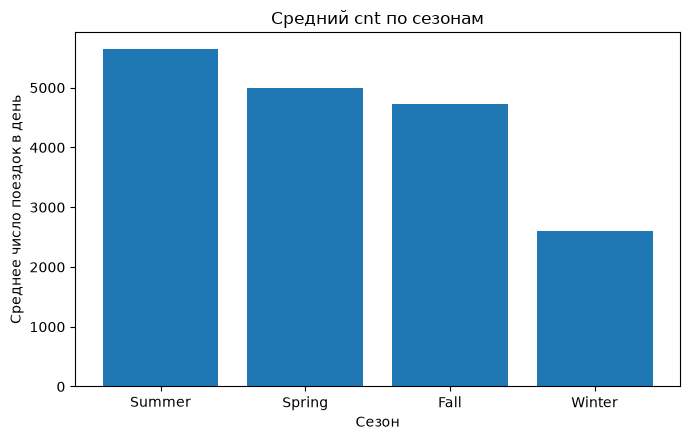

In [13]:
order = season_cnt.index
plt.figure(figsize=(7, 4.5))
plt.bar(order, bike.groupby("season_label", observed=True)["cnt"].mean().reindex(order))
plt.title("Средний cnt по сезонам")
plt.xlabel("Сезон")
plt.ylabel("Среднее число поездок в день")
plt.tight_layout()
plt.show()

### 4.7 Визуализация №2 — распределение общего спроса (cnt)

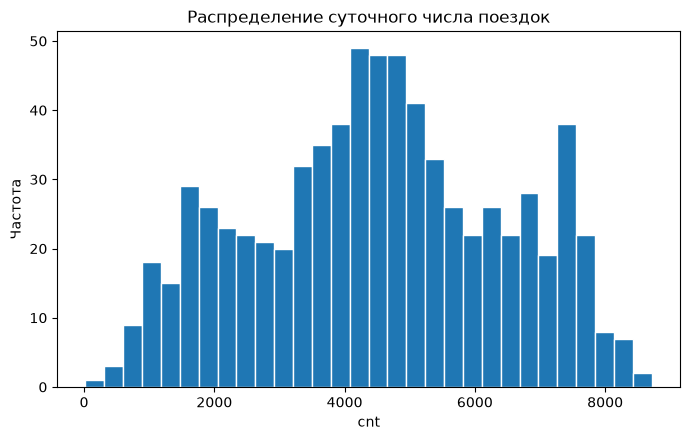

In [14]:
plt.figure(figsize=(7, 4.5))
plt.hist(bike["cnt"], bins=30, edgecolor="white")
plt.title("Распределение суточного числа поездок")
plt.xlabel("cnt")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

Распределение похоже на смесь двух режимов — есть заметная группа дней с
низким спросом (холодный сезон/плохая погода) и основная масса дней со
спросом выше 4000 поездок.

### 4.8 Визуализация №3 — взаимосвязь температуры и спроса

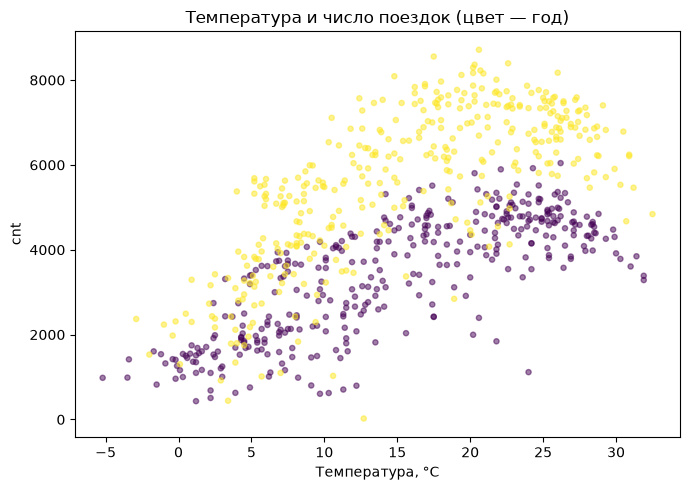

In [15]:
plt.figure(figsize=(7, 5))
plt.scatter(bike["temp_c"], bike["cnt"], s=14, alpha=0.5, c=bike["yr"].astype(int))
plt.title("Температура и число поездок (цвет — год)")
plt.xlabel("Температура, °C")
plt.ylabel("cnt")
plt.tight_layout()
plt.show()

Видна отчётливая положительная связь: с ростом температуры число поездок
растёт, хотя при очень высокой температуре рост немного замедляется (жара уже
не так комфортна для поездки). Более тёмные точки (2012 год) в среднем выше —
сервис явно вырос за второй год наблюдений.

### 4.9 Визуализация №4 — временной ряд (обязателен, так как есть дата)

Дневной ряд зашумлён, поэтому дополнительно строю агрегацию по месяцам —
это и есть требуемая "временная агрегация" для набора с датой.

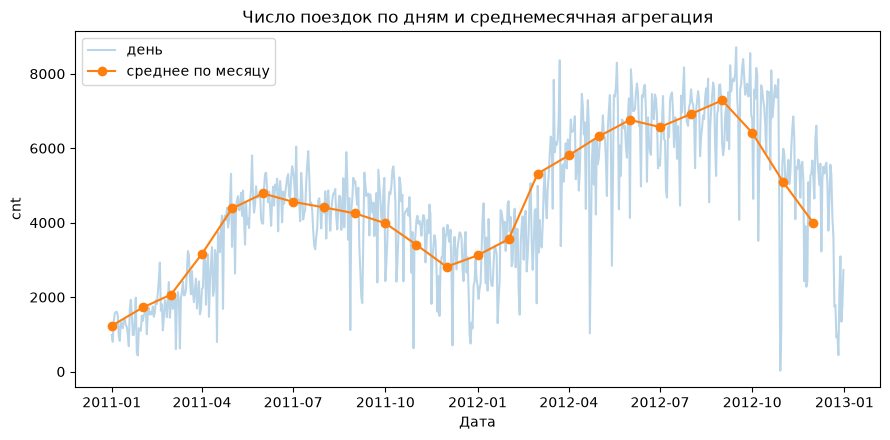

In [16]:
monthly = bike.set_index("dteday")["cnt"].resample("MS").mean()

plt.figure(figsize=(9, 4.5))
plt.plot(bike["dteday"], bike["cnt"], alpha=0.3, label="день")
plt.plot(monthly.index, monthly.values, marker="o", label="среднее по месяцу")
plt.title("Число поездок по дням и среднемесячная агрегация")
plt.xlabel("Дата")
plt.ylabel("cnt")
plt.legend()
plt.tight_layout()
plt.show()

Среднемесячная агрегация явно показывает сезонную волну: минимум приходится на
зимние месяцы (2011-01, ≈1232
поездок в день), максимум — на тёплый сезон
(2012-09, ≈7286). Хорошо видно и
общий рост между 2011 и 2012 годом — второй год почти везде выше первого на
том же месяце.

## 5. Экспорт

Сохраняю подготовленную таблицу (с новыми признаками и оптимизированными
типами) в CSV, JSON Lines и Parquet, в ту же папку `output`, что и для
FiresRu, но под своим именем файлов.

In [17]:
from pathlib import Path

OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

bike.to_csv(OUT_DIR / "BikeSharing_prepared.csv", index=False, encoding="utf-8")
bike.to_json(OUT_DIR / "BikeSharing_prepared.json", orient="records", lines=True,
             force_ascii=False, date_format="iso")
bike.to_parquet(OUT_DIR / "BikeSharing_prepared.parquet", index=False,
                engine="pyarrow", compression="snappy")

for path in OUT_DIR.glob("BikeSharing_prepared.*"):
    print(f"{path.name:28s} {path.stat().st_size / 1024:7.1f} KB")

BikeSharing_prepared.csv        71.9 KB
BikeSharing_prepared.json      227.3 KB
BikeSharing_prepared.parquet    61.4 KB


In [18]:
csv_back = pd.read_csv(OUT_DIR / "BikeSharing_prepared.csv")
parquet_back = pd.read_parquet(OUT_DIR / "BikeSharing_prepared.parquet")

print("CSV:", csv_back.shape, " dtype dteday:", csv_back["dteday"].dtype)
print("Parquet:", parquet_back.shape, " dtype dteday:", parquet_back["dteday"].dtype)
print("\ndtype season после CSV:", csv_back["season"].dtype)
print("dtype season после Parquet:", parquet_back["season"].dtype)

CSV: (731, 20)  dtype dteday: str
Parquet: (731, 20)  dtype dteday: datetime64[us]

dtype season после CSV: int64
dtype season после Parquet: int64


Здесь картина интереснее, чем в части по FiresRu. После CSV, как и ожидалось,
`dteday` снова стал обычной строкой, а `season` — числом: текстовый формат не
хранит схему вообще. Parquet восстановил `dteday` как настоящий `datetime64`
без единой дополнительной строки кода — то есть дата, в отличие от CSV,
осталась датой. А вот `season` после Parquet тоже вернулся как `int64`, а не
`category` — в отличие от `type_name` в части по FiresRu. Разница в том, что
там `category` была построена из **текстовых** значений, а здесь — из
**целочисленных** кодов: в этой связке версий pandas/pyarrow категориальный
признак на основе чисел через Parquet сохраняется только на уровне значений,
а не как отдельный `category`-dtype. Значит рассчитывать, что "Parquet сам всё
восстановит", можно не для любой категории — это стоит явно проверять round-trip'ом,
а не считать само собой разумеющимся.

## 6. Итог

**Выводы:**

1. Набор содержит 731 строку и 16 столбцов, пропусков и полных дубликатов нет;
   `cnt` во всех строках точно равен сумме `casual` и `registered` — данные
   внутренне согласованы.
2. Спрос на аренду сильно сезонный: летние месяцы дают в разы больше поездок,
   чем зимние, и это видно и по группировке, и по временной агрегации.
3. Температура положительно связана с числом поездок (заметно сильнее, чем
   любая погодная корреляция в FiresRu), но связь не строго линейна — при
   очень высокой температуре рост спроса замедляется.
4. Структура спроса отличается по типу дня: доля разовых (`casual`) поездок
   заметно выше в выходные и праздники, чем в рабочие дни — сервис используется
   по-разному в будни и на отдыхе.
5. Сервис заметно вырос за второй год наблюдений (2012 в среднем выше 2011 по
   тем же месяцам) — это не сезонный, а трендовый эффект.
6. По правилу IQR у `cnt` нет ни одного выброса ни сверху, ни снизу —
   распределение суточного спроса компактное, без тяжёлых хвостов, в отличие
   от `wind_speed_ms` в FiresRu (там кандидатов было 13,7%).

**Ограничения анализа:**

1. Данные агрегированы по дням для одного города и одной сети велопроката —
   выводы нельзя переносить на другие города или почасовую динамику без
   отдельной проверки.
2. Единица измерения `windspeed` в источнике не уточнена (известен только
   делитель нормировки, 67), поэтому абсолютное значение скорости ветра в
   реальных единицах не восстановлено — использовалась только нормированная
   величина.